# Statistical Learning - TP 2

**M2 EI2D & MATD - Université Paris 13, Institut Galilée**

**Noms :** ................................ / ................................

---

## Sommaire

1. **Exercice 1** - Comparaison de deux modèles à partir de leurs matrices de confusion
   - Q1. Estimation de la loi de $Y$
   - Q2. Vérifications de cohérence entre $\mathcal D$ et $\mathcal D'$
   - Q3. Accuracy de chaque modèle
   - Q4. Meilleur modèle selon la perte $L_b$ (risque empirique)
   - Q5. Est-ce le meilleur modèle pour le vrai risque ?
   - Q6. Risque empirique avec la perte $\ell_2$
2. **Exercice 2** - Code Python général pour comparer deux modèles avec $L_b$
3. **Conclusion**

---

### Conventions et notations

- $Y \in \mathcal Y = \{A, B, C\}$ est la variable à prédire.
- Dans une matrice de confusion $M$, **les lignes sont les valeurs prédites** $p$ et **les colonnes les vraies valeurs** $t$ :
  $M_{p,t}$ = nombre d'individus de $\mathcal D'$ de vraie classe $t$ prédits dans la classe $p$.
- $n = \sum_{p,t} M_{p,t}$ est la taille de $\mathcal D'$.
- Pour une fonction de perte $\ell$, le risque empirique d'un modèle $g$ sur $\mathcal D'$ est
$$\hat R_\ell(g) = \frac1n \sum_{i=1}^n \ell\big(g(x_i), y_i\big) = \frac1n \sum_{p,t} M_{p,t}\,\ell(p,t).$$

Cette dernière formule est pratique : le risque empirique se calcule directement à partir de la matrice de confusion,
sans avoir besoin des données individu par individu.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

---

# Exercice 1

### Les données

On saisit les deux matrices de confusion de l'énoncé. On utilise des `DataFrame` pandas pour que l'affichage soit lisible
(lignes = prédictions, colonnes = vraies classes).

In [2]:
classes = ["A", "B", "C"]

g1 = np.array([[44,  0,  0],
               [ 5, 62,  1],
               [ 1,  8, 54]])

g2 = np.array([[44,  4,  5],
               [ 2, 64,  3],
               [ 4,  2, 47]])

def afficher_matrice(M, nom):
    df = pd.DataFrame(M, index=["prédit " + c for c in classes], columns=["vrai " + c for c in classes])
    print(f"Matrice de confusion de {nom} :")
    print(df, "\n")

afficher_matrice(g1, "g1")
afficher_matrice(g2, "g2")

Matrice de confusion de g1 :
          vrai A  vrai B  vrai C
prédit A      44       0       0
prédit B       5      62       1
prédit C       1       8      54 

Matrice de confusion de g2 :
          vrai A  vrai B  vrai C
prédit A      44       4       5
prédit B       2      64       3
prédit C       4       2      47 



## Question 1 - Estimation de la loi de $Y$

Comme les colonnes correspondent aux **vraies** classes, la somme de la colonne $t$ donne le nombre d'individus de $\mathcal D'$
dont la vraie classe est $t$, quelles que soient les prédictions du modèle. On estime donc
$$\hat P(Y = y) = \frac{\text{somme de la colonne } y}{n}.$$

**Calcul à la main (matrice de $g_1$) :**

- colonne A : $44 + 5 + 1 = 50$
- colonne B : $0 + 62 + 8 = 70$
- colonne C : $0 + 1 + 54 = 55$
- total : $n = 50 + 70 + 55 = 175$

D'où
$$\hat P(Y=A) = \frac{50}{175} = \frac27 \approx 0.286,\qquad \hat P(Y=B) = \frac{70}{175} = \frac25 = 0.400,\qquad \hat P(Y=C) = \frac{55}{175} = \frac{11}{35} \approx 0.314.$$

Avec la matrice de $g_2$ on obtient exactement les mêmes sommes de colonnes ($44+2+4 = 50$, $4+64+2 = 70$, $5+3+47 = 55$),
ce qui est normal puisque les deux modèles sont évalués sur le même ensemble $\mathcal D'$.

In [3]:
def loi_de_Y(M):
    # somme de chaque colonne (vraies classes) divisée par le nombre total d'individus
    effectifs = M.sum(axis=0)
    return effectifs, effectifs / M.sum()

eff1, loi1 = loi_de_Y(g1)
eff2, loi2 = loi_de_Y(g2)

tableau = pd.DataFrame({"effectif (g1)": eff1, "P(Y=y) (g1)": loi1.round(3),
                        "effectif (g2)": eff2, "P(Y=y) (g2)": loi2.round(3)}, index=classes)
print(tableau)
print("\nTaille de D' :", g1.sum(), "(g1) et", g2.sum(), "(g2)")

   effectif (g1)  P(Y=y) (g1)  effectif (g2)  P(Y=y) (g2)
A             50        0.286             50        0.286
B             70        0.400             70        0.400
C             55        0.314             55        0.314

Taille de D' : 175 (g1) et 175 (g2)


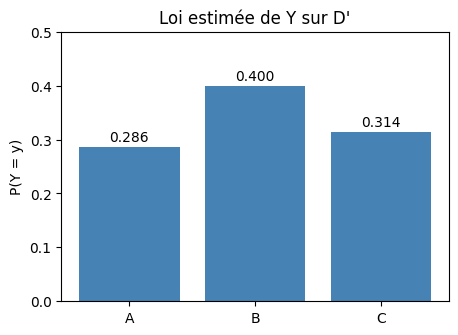

In [4]:
plt.figure(figsize=(5, 3.5))
plt.bar(classes, loi1, color="steelblue")
for i in range(3):
    plt.text(i, loi1[i] + 0.01, f"{loi1[i]:.3f}", ha="center")
plt.ylim(0, 0.5)
plt.ylabel("P(Y = y)")
plt.title("Loi estimée de Y sur D'")
plt.show()

**Conclusion Q1 :** $\hat P(Y=A) \approx 0.286$, $\hat P(Y=B) = 0.400$, $\hat P(Y=C) \approx 0.314$.
Les classes sont un peu déséquilibrées (B est la plus fréquente) mais aucune n'est rare.

## Question 2 - Vérifications de cohérence entre $\mathcal D$ et $\mathcal D'$

Pour que l'évaluation sur $\mathcal D'$ ait un sens, il faut au minimum vérifier :

1. **Les deux matrices portent sur le même ensemble $\mathcal D'$** : même nombre total d'individus et mêmes sommes de colonnes
   (mêmes vraies classes). C'est le cas ici : $n = 175$ et les colonnes valent $(50, 70, 55)$ pour les deux modèles.
2. **$\mathcal D$ et $\mathcal D'$ sont disjoints** : $\mathcal D'$ ne doit contenir aucun individu ayant servi à l'apprentissage,
   sinon le risque calculé sur $\mathcal D'$ est trop optimiste.
3. **$\mathcal D$ et $\mathcal D'$ suivent la même loi** : les mêmes variables, codées de la même façon, et des proportions de classes
   proches. Concrètement, on compare la loi de $Y$ estimée à la question 1 avec les proportions de A, B, C dans $\mathcal D$.
   Si elles sont très différentes, $\mathcal D'$ n'est pas représentatif du problème sur lequel le modèle a été appris.
4. **Les mêmes classes** apparaissent dans $\mathcal D$ et $\mathcal D'$ (ici $\{A, B, C\}$ dans les deux cas).

On ne dispose pas de $\mathcal D$, donc on ne peut faire ici que la vérification 1, avec le code ci-dessous.

In [5]:
def verifier_coherence(M1, M2):
    meme_taille = M1.shape == M2.shape
    meme_n = M1.sum() == M2.sum()
    memes_colonnes = np.array_equal(M1.sum(axis=0), M2.sum(axis=0))
    print("Même dimension          :", meme_taille)
    print("Même nombre d'individus :", meme_n, f"({M1.sum()} et {M2.sum()})")
    print("Mêmes vraies classes    :", memes_colonnes, M1.sum(axis=0), M2.sum(axis=0))
    return meme_taille and meme_n and memes_colonnes

coherent = verifier_coherence(g1, g2)

Même dimension          : True
Même nombre d'individus : True (175 et 175)
Mêmes vraies classes    : True [50 70 55] [50 70 55]


## Question 3 - Accuracy de chaque modèle

Les bonnes classifications sont sur la diagonale de la matrice de confusion (prédit = vrai), donc
$$\text{accuracy}(g) = \frac{\operatorname{trace}(M)}{n}.$$

**Calcul à la main :**

- $g_1$ : $44 + 62 + 54 = 160$ bonnes réponses, donc $\text{acc}(g_1) = \dfrac{160}{175} \approx 0.9143$, soit **91.43 %**.
- $g_2$ : $44 + 64 + 47 = 155$ bonnes réponses, donc $\text{acc}(g_2) = \dfrac{155}{175} \approx 0.8857$, soit **88.57 %**.

In [6]:
def accuracy(M):
    return np.trace(M) / M.sum()

print(f"Accuracy de g1 : {np.trace(g1)}/{g1.sum()} = {accuracy(g1):.4f}  ({100*accuracy(g1):.2f} %)")
print(f"Accuracy de g2 : {np.trace(g2)}/{g2.sum()} = {accuracy(g2):.4f}  ({100*accuracy(g2):.2f} %)")

Accuracy de g1 : 160/175 = 0.9143  (91.43 %)
Accuracy de g2 : 155/175 = 0.8857  (88.57 %)


On peut aussi regarder le taux de bonnes réponses **par classe** (le rappel : diagonale divisée par la somme de la colonne),
pour voir où chaque modèle se trompe :

In [7]:
def rappel_par_classe(M):
    return np.diag(M) / M.sum(axis=0)

print(pd.DataFrame({"g1": rappel_par_classe(g1).round(3), "g2": rappel_par_classe(g2).round(3)}, index=classes))

      g1     g2
A  0.880  0.880
B  0.886  0.914
C  0.982  0.855


Les deux modèles sont à égalité sur la classe A (88 %). $g_2$ est un peu meilleur sur B (91.4 % contre 88.6 %), mais $g_1$ est
nettement meilleur sur C (98.2 % contre 85.5 %). Les erreurs de $g_1$ sont concentrées : 8 individus de classe B prédits C et
5 individus de classe A prédits B. Celles de $g_2$ sont plus dispersées (par exemple 5 individus de classe C prédits A).

## Question 4 - Meilleur modèle selon $L_b(p,t) = \mathbf 1_{p\neq t}$

Avec la perte 0-1, chaque erreur coûte 1 et chaque bonne réponse coûte 0. Le risque empirique est donc la proportion d'erreurs :
$$\hat R_{L_b}(g) = \frac1n \sum_{p\neq t} M_{p,t} = 1 - \text{accuracy}(g).$$

**Calcul à la main :**

- $g_1$ : $175 - 160 = 15$ erreurs, donc $\hat R_{L_b}(g_1) = \dfrac{15}{175} \approx 0.0857$
- $g_2$ : $175 - 155 = 20$ erreurs, donc $\hat R_{L_b}(g_2) = \dfrac{20}{175} \approx 0.1143$

$\hat R_{L_b}(g_1) < \hat R_{L_b}(g_2)$, donc **selon le risque empirique sur $\mathcal D'$, le meilleur modèle est $g_1$**.

Pour le code, on écrit une fonction générale qui calcule le risque empirique pour **n'importe quelle** matrice de perte,
en utilisant la formule $\hat R_\ell(g) = \frac1n\sum_{p,t} M_{p,t}\,\ell(p,t)$. Elle resservira à la question 6.

In [8]:
def risque_empirique(M, L):
    # M : matrice de confusion (lignes = prédit, colonnes = vrai)
    # L : matrice de perte, L[p, t] = coût de prédire p quand la vraie valeur est t
    return np.sum(M * L) / M.sum()

# perte 0-1 : 0 sur la diagonale, 1 ailleurs
Lb = 1 - np.eye(3)
print("Matrice de perte Lb :\n", Lb, "\n")

R1 = risque_empirique(g1, Lb)
R2 = risque_empirique(g2, Lb)
print(f"Risque empirique de g1 : {R1:.4f}")
print(f"Risque empirique de g2 : {R2:.4f}")
print("Meilleur modèle selon Lb :", "g1" if R1 < R2 else "g2")

Matrice de perte Lb :
 [[0. 1. 1.]
 [1. 0. 1.]
 [1. 1. 0.]] 

Risque empirique de g1 : 0.0857
Risque empirique de g2 : 0.1143
Meilleur modèle selon Lb : g1


## Question 5 - Le modèle choisi est-il le meilleur pour le vrai risque ?

**Pas forcément.** Le vrai risque est $R_{L_b}(g) = \mathbb E\big[L_b(g(X), Y)\big] = P\big(g(X) \neq Y\big)$, calculé sur toute la
population. Nous n'en avons qu'une **estimation** $\hat R_{L_b}(g)$ à partir de $n = 175$ individus. Cette estimation est sans biais
(si $\mathcal D'$ est indépendant de $\mathcal D$) mais elle a une variance : si on prenait un autre ensemble $\mathcal D'$,
on trouverait d'autres valeurs.

Pour savoir si la différence entre $g_1$ et $g_2$ est significative, on peut calculer un **intervalle de confiance** pour chaque risque.
Le nombre d'erreurs suit une loi binomiale $\mathcal B(n, R)$, donc (approximation normale)
$$\hat R \pm 1.96\sqrt{\frac{\hat R(1-\hat R)}{n}}$$
est un intervalle de confiance à environ 95 %.

On peut aussi utiliser l'inégalité de Hoeffding, qui ne demande aucune approximation : avec probabilité au moins $1-\delta$,
$$|\hat R - R| \le \varepsilon = \sqrt{\frac{\ln(2/\delta)}{2n}}.$$

In [9]:
n = g1.sum()

def intervalle_confiance(R, n, z=1.96):
    marge = z * np.sqrt(R * (1 - R) / n)
    return R - marge, R + marge

for nom, R in [("g1", R1), ("g2", R2)]:
    a, b = intervalle_confiance(R, n)
    print(f"{nom} : R_emp = {R:.4f}   IC 95 % = [{a:.4f} ; {b:.4f}]")

delta = 0.05
eps = np.sqrt(np.log(2 / delta) / (2 * n))
print(f"\nHoeffding (delta = {delta}) : epsilon = {eps:.4f}")
print(f"Écart observé entre les deux risques : {R2 - R1:.4f}")

g1 : R_emp = 0.0857   IC 95 % = [0.0442 ; 0.1272]
g2 : R_emp = 0.1143   IC 95 % = [0.0671 ; 0.1614]

Hoeffding (delta = 0.05) : epsilon = 0.1027
Écart observé entre les deux risques : 0.0286


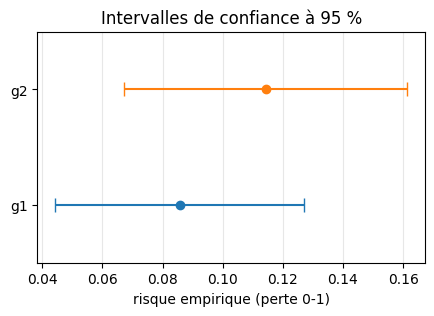

In [10]:
plt.figure(figsize=(5, 3))
for i, (nom, R) in enumerate([("g1", R1), ("g2", R2)]):
    a, b = intervalle_confiance(R, n)
    plt.errorbar(R, i, xerr=[[R - a], [b - R]], fmt="o", capsize=5)
plt.yticks([0, 1], ["g1", "g2"])
plt.ylim(-0.5, 1.5)
plt.xlabel("risque empirique (perte 0-1)")
plt.title("Intervalles de confiance à 95 %")
plt.grid(axis="x", alpha=0.3)
plt.show()

**Interprétation :** les deux intervalles de confiance se chevauchent largement, et l'écart entre les risques empiriques
($\approx 0.029$, soit 5 erreurs) est bien plus petit que la précision donnée par Hoeffding ($\varepsilon \approx 0.10$).
On ne peut donc **pas affirmer** que $g_1$ a un vrai risque plus petit que $g_2$.

**Conclusion Q5 :** $g_1$ est le meilleur choix au vu des données disponibles (c'est le minimiseur du risque empirique), mais rien ne
garantit que ce soit le meilleur pour le vrai risque $R_{L_b}$. Pour conclure il faudrait plus de données de test, ou un test
apparié (test de McNemar), qui demanderait de connaître les prédictions des deux modèles individu par individu.

## Question 6 - Risque empirique avec la perte $\ell_2$

La matrice de perte est (lignes = $p$ prédit, colonnes = $t$ vrai) :

| $\ell_2(p,t)$ | A | B | C |
|---|---|---|---|
| **A** | 0 | 2 | 1 |
| **B** | 1 | 0 | 1 |
| **C** | 2 | 1 | 0 |

On calcule $\hat R_{\ell_2}(g) = \frac1n\sum_{p,t} M_{p,t}\,\ell_2(p,t)$ en faisant le produit terme à terme des deux matrices.

**Calcul à la main pour $g_1$** (ligne par ligne) :

- ligne A : $44\times 0 + 0\times 2 + 0\times 1 = 0$
- ligne B : $5\times 1 + 62\times 0 + 1\times 1 = 6$
- ligne C : $1\times 2 + 8\times 1 + 54\times 0 = 10$

Total $= 16$, donc $\hat R_{\ell_2}(g_1) = \dfrac{16}{175} \approx 0.0914$.

**Calcul à la main pour $g_2$** :

- ligne A : $44\times 0 + 4\times 2 + 5\times 1 = 13$
- ligne B : $2\times 1 + 64\times 0 + 3\times 1 = 5$
- ligne C : $4\times 2 + 2\times 1 + 47\times 0 = 10$

Total $= 28$, donc $\hat R_{\ell_2}(g_2) = \dfrac{28}{175} = 0.16$.

In [11]:
L2 = np.array([[0, 2, 1],
               [1, 0, 1],
               [2, 1, 0]])

for nom, M in [("g1", g1), ("g2", g2)]:
    cout_par_ligne = (M * L2).sum(axis=1)
    print(f"{nom} : coût par ligne (A, B, C) = {cout_par_ligne}, total = {cout_par_ligne.sum()}, "
          f"risque = {risque_empirique(M, L2):.4f}")

g1 : coût par ligne (A, B, C) = [ 0  6 10], total = 16, risque = 0.0914
g2 : coût par ligne (A, B, C) = [13  5 10], total = 28, risque = 0.1600


**Conclusion Q6 :** $\hat R_{\ell_2}(g_1) \approx 0.091 < \hat R_{\ell_2}(g_2) = 0.16$, donc $g_1$ reste le meilleur avec la perte $\ell_2$,
et l'écart est même plus grand qu'avec $L_b$. En effet $\ell_2$ pénalise fortement (coût 2) le fait de prédire A quand la vraie
classe est B, et de prédire C quand la vraie classe est A. Or $g_2$ fait 4 erreurs de chacun de ces deux types, alors que $g_1$
n'en fait qu'une (C prédit au lieu de A).

### Récapitulatif de l'exercice 1

In [12]:
recap = pd.DataFrame({
    "Accuracy": [accuracy(g1), accuracy(g2)],
    "Risque empirique Lb": [risque_empirique(g1, Lb), risque_empirique(g2, Lb)],
    "Risque empirique l2": [risque_empirique(g1, L2), risque_empirique(g2, L2)],
}, index=["g1", "g2"]).round(4)
print(recap)

    Accuracy  Risque empirique Lb  Risque empirique l2
g1    0.9143               0.0857               0.0914
g2    0.8857               0.1143               0.1600


---

# Exercice 2

On veut un code Python qui, à partir des matrices de confusion de deux modèles $g_1$ et $g_2$ de dimension $m \times m$
quelconque, détermine le meilleur modèle pour la perte $L_b(p,t) = \mathbf 1_{p\neq t}$.

**Démarche :**

1. Vérifier que les entrées sont valides : matrices carrées, de même dimension $m$, à coefficients positifs, et évaluées sur le même
   ensemble de test (même effectif total et mêmes sommes de colonnes, comme à la question 2).
2. Construire la matrice de perte $L_b = J_m - I_m$ (des 1 partout sauf 0 sur la diagonale).
3. Calculer le risque empirique de chaque modèle : $\hat R(g) = \frac1n\sum_{p,t} M_{p,t} L_b(p,t) = 1 - \frac{\operatorname{trace}(M)}{n}$.
4. Renvoyer le modèle de plus petit risque (ou signaler une égalité).

On réutilise la fonction `risque_empirique` de l'exercice 1, ce qui permet en plus de changer facilement de fonction de perte.

In [13]:
def perte_0_1(m):
    # matrice de perte Lb de taille m x m : 0 sur la diagonale, 1 ailleurs
    return np.ones((m, m)) - np.eye(m)


def verifier_matrices(M1, M2):
    # vérifie que les deux matrices de confusion sont utilisables et comparables
    M1, M2 = np.asarray(M1), np.asarray(M2)
    if M1.ndim != 2 or M1.shape[0] != M1.shape[1]:
        raise ValueError("La matrice de g1 doit être carrée.")
    if M1.shape != M2.shape:
        raise ValueError("Les deux matrices doivent avoir la même dimension m.")
    if (M1 < 0).any() or (M2 < 0).any():
        raise ValueError("Une matrice de confusion ne contient que des effectifs positifs.")
    if M1.sum() == 0 or M2.sum() == 0:
        raise ValueError("Une matrice de confusion est vide.")
    if not np.array_equal(M1.sum(axis=0), M2.sum(axis=0)):
        print("Attention : les sommes des colonnes sont différentes, "
              "les deux modèles ne semblent pas évalués sur le même ensemble de test.")
    return M1, M2


def meilleur_modele(M1, M2, L=None, noms=("g1", "g2"), afficher=True):
    # compare deux modèles à partir de leurs matrices de confusion (lignes = prédit, colonnes = vrai)
    # par défaut on utilise la perte 0-1 ; on peut donner une autre matrice de perte L
    M1, M2 = verifier_matrices(M1, M2)
    m = M1.shape[0]
    if L is None:
        L = perte_0_1(m)

    R1 = risque_empirique(M1, L)
    R2 = risque_empirique(M2, L)

    if R1 < R2:
        gagnant = noms[0]
    elif R2 < R1:
        gagnant = noms[1]
    else:
        gagnant = "égalité"

    if afficher:
        print(f"Dimension m = {m}, taille de l'ensemble de test n = {M1.sum()}")
        print(f"Risque empirique de {noms[0]} : {R1:.4f}")
        print(f"Risque empirique de {noms[1]} : {R2:.4f}")
        print("Meilleur modèle :", gagnant)
    return gagnant, R1, R2

### Test 1 : les matrices de l'exercice 1 ($m = 3$)

On doit retrouver les résultats des questions 4 et 6.

In [14]:
print("Perte Lb :")
resultat = meilleur_modele(g1, g2)
print("\nPerte l2 :")
resultat = meilleur_modele(g1, g2, L=L2)

Perte Lb :
Dimension m = 3, taille de l'ensemble de test n = 175
Risque empirique de g1 : 0.0857
Risque empirique de g2 : 0.1143
Meilleur modèle : g1

Perte l2 :
Dimension m = 3, taille de l'ensemble de test n = 175
Risque empirique de g1 : 0.0914
Risque empirique de g2 : 0.1600
Meilleur modèle : g1


### Test 2 : un exemple avec $m = 2$

On reprend l'exercice 2 de la feuille d'exercices 1 (classes $-1$ et $1$). Les matrices de confusion étaient
$\begin{pmatrix}3 & 1\\ 2 & 4\end{pmatrix}$ pour $g_1$ et $\begin{pmatrix}4 & 3\\ 1 & 2\end{pmatrix}$ pour $g_2$,
avec des risques empiriques $0.3$ et $0.4$ pour la perte 0-1.

In [15]:
h1 = np.array([[3, 1],
               [2, 4]])
h2 = np.array([[4, 3],
               [1, 2]])
resultat = meilleur_modele(h1, h2)

Dimension m = 2, taille de l'ensemble de test n = 10
Risque empirique de g1 : 0.3000
Risque empirique de g2 : 0.4000
Meilleur modèle : g1


### Test 3 : une dimension plus grande ($m = 5$), générée au hasard

On simule un ensemble de test de 500 individus répartis en 5 classes, et deux modèles qui se trompent avec des probabilités
différentes (environ 10 % d'erreur pour le premier, 20 % pour le second). On construit les matrices de confusion à partir des
prédictions, puis on applique notre fonction.

In [16]:
rng = np.random.default_rng(0)
m, n_test = 5, 500
y_vrai = rng.integers(0, m, size=n_test)

def predictions_bruitees(y, taux_erreur):
    # on garde la vraie classe, sauf avec probabilité taux_erreur où on tire une autre classe au hasard
    pred = y.copy()
    erreurs = rng.random(len(y)) < taux_erreur
    pred[erreurs] = (y[erreurs] + rng.integers(1, m, size=erreurs.sum())) % m
    return pred

def matrice_confusion(pred, vrai, m):
    M = np.zeros((m, m), dtype=int)
    for p, t in zip(pred, vrai):
        M[p, t] += 1
    return M

M_a = matrice_confusion(predictions_bruitees(y_vrai, 0.10), y_vrai, m)
M_b = matrice_confusion(predictions_bruitees(y_vrai, 0.20), y_vrai, m)
print("Matrice du modèle a :\n", M_a)
print("Matrice du modèle b :\n", M_b, "\n")
resultat = meilleur_modele(M_a, M_b, noms=("modèle a", "modèle b"))

Matrice du modèle a :
 [[ 92   4   0   2   6]
 [  1  75   3   3   2]
 [  1   1  95   2   0]
 [  1   0   0  93   2]
 [  4   1   4   1 107]]
Matrice du modèle b :
 [[73  2  7  6  3]
 [ 8 70  2  7  4]
 [ 3  4 84  4  4]
 [ 7  3  4 79 12]
 [ 8  2  5  5 94]] 

Dimension m = 5, taille de l'ensemble de test n = 500
Risque empirique de modèle a : 0.0760
Risque empirique de modèle b : 0.2000
Meilleur modèle : modèle a


### Test 4 : les vérifications fonctionnent

Si les matrices n'ont pas la même dimension, la fonction refuse de les comparer :

In [17]:
try:
    meilleur_modele(g1, h1)
except ValueError as erreur:
    print("Erreur détectée :", erreur)

Erreur détectée : Les deux matrices doivent avoir la même dimension m.


---

# Conclusion

- **Loi de $Y$ :** à partir des sommes de colonnes, $\hat P(A) \approx 0.286$, $\hat P(B) = 0.400$, $\hat P(C) \approx 0.314$ sur $n = 175$ individus.
- **Cohérence :** les deux matrices portent bien sur le même ensemble $\mathcal D'$ ; il faudrait aussi vérifier que $\mathcal D'$ est
  disjoint de $\mathcal D$ et qu'il suit la même loi.
- **Accuracy :** $91.43\,\%$ pour $g_1$ contre $88.57\,\%$ pour $g_2$.
- **Perte $L_b$ :** $g_1$ a le plus petit risque empirique ($0.086$ contre $0.114$), mais l'écart n'est pas significatif avec 175 individus :
  on ne peut pas garantir que $g_1$ est meilleur pour le vrai risque.
- **Perte $\ell_2$ :** $g_1$ reste meilleur ($0.091$ contre $0.160$), car $g_2$ fait davantage d'erreurs coûteuses.
- **Exercice 2 :** la fonction `meilleur_modele` compare deux modèles pour une dimension $m$ quelconque, à partir de leurs seules
  matrices de confusion, avec la perte 0-1 par défaut ou toute autre matrice de perte.